In [1]:
from delays.config import FEATURES, TARGET
from delays.data import prepare
from delays.registry import MODELS, get_model
from delays.validation import validate, train_final

df, train_df, val_df, X_test, gare_freq = prepare()

In [2]:
df

,train,gare,date,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4,p0q0,holidays,quarter,gare_freq,propagation_index,propagation_index_2,gare_arret
0,VBXNMF,KYF,2023-04-03,8,0.0,0.0,1.0,-3.0,-1.0,-2.0,-1.0,0,2,29737,0.2,-2.2,KYF_8
1,EVCECW,ZFB,2023-04-03,21,0.0,-1.0,0.0,0.0,1.0,0.0,1.0,0,2,18559,-0.3,0.3,ZFB_21
2,EVCECW,AUW,2023-04-03,20,-1.0,0.0,-1.0,1.0,0.0,1.0,0.0,0,2,5758,-0.7,0.7,AUW_20
3,EVCECW,YWQ,2023-04-03,19,0.0,-1.0,-1.0,0.0,1.0,0.0,0.0,0,2,5751,-0.5,0.3,YWQ_19
4,EVCECW,MZE,2023-04-03,18,-1.0,-1.0,1.0,-2.0,0.0,0.0,-1.0,0,2,6758,-0.6,-1.0,MZE_18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667252,QDHZQQ,UAK,2023-11-10,11,2.0,3.0,0.0,1.0,0.0,2.0,0.0,0,4,14296,1.9,0.9,UAK_11
667253,QDHZQQ,NZC,2023-11-10,10,3.0,0.0,0.0,1.0,0.0,1.0,-1.0,0,4,6784,1.5,0.7,NZC_10
667254,QDHZQQ,FFU,2023-11-10,9,0.0,0.0,-1.0,0.0,2.0,1.0,2.0,0,4,6773,-0.2,0.8,FFU_9
667255,QDHZQQ,KCK,2023-11-10,20,-1.0,0.0,-1.0,-2.0,-1.0,-1.0,0.0,0,4,21449,-0.7,-1.5,KCK_20


array([[<Axes: title={'center': 'p2q0'}>,
        <Axes: title={'center': 'p3q0'}>,
        <Axes: title={'center': 'p4q0'}>],
       [<Axes: title={'center': 'p0q2'}>,
        <Axes: title={'center': 'p0q3'}>,
        <Axes: title={'center': 'p0q4'}>],
       [<Axes: title={'center': 'p0q0'}>, <Axes: >, <Axes: >]],
      dtype=object)

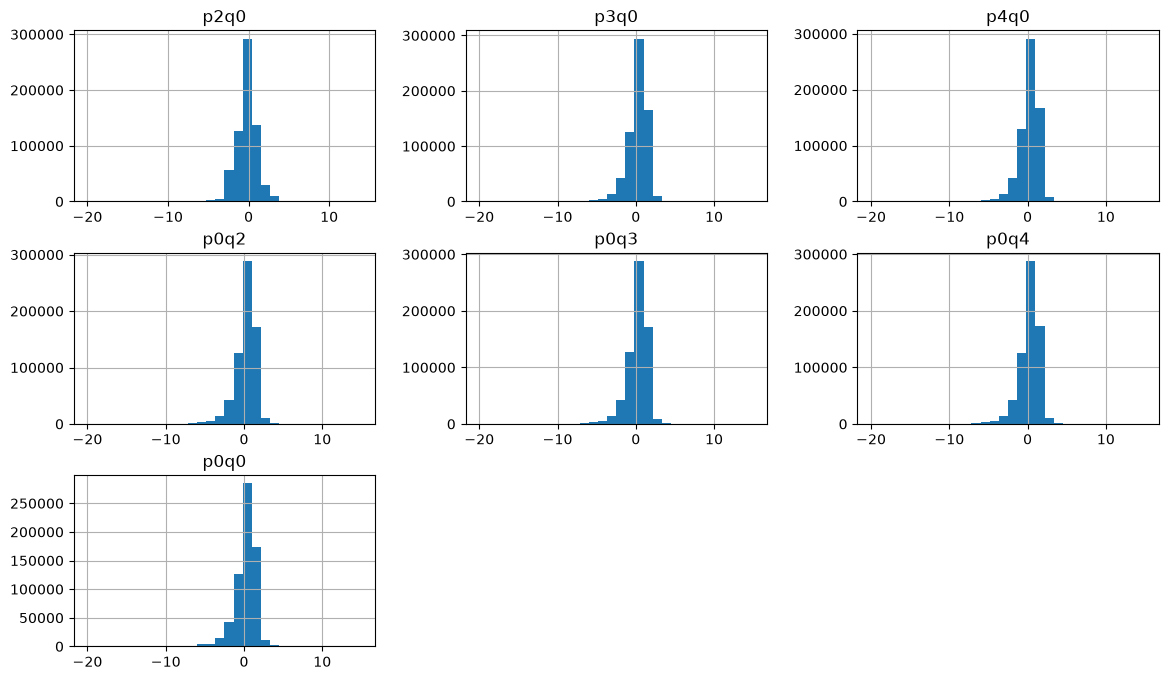

In [8]:
cols = ["p2q0","p3q0","p4q0","p0q2","p0q3","p0q4","p0q0"]

df[cols].hist(bins=30, figsize=(14,8))

In [4]:
df.groupby("p2q0")["p0q0"].mean()

p2q0
-20.0   -1.504950
-19.0   -1.342857
-18.0   -1.904762
-17.0   -1.666667
-16.0   -1.140845
-15.0   -0.859649
-14.0   -1.992308
-13.0   -1.812903
-12.0   -1.091429
-11.0   -0.882051
-10.0   -1.253247
-9.0    -1.021505
-8.0    -0.670370
-7.0    -0.705952
-6.0    -0.401830
-5.0    -0.092117
-4.0     0.165618
-3.0     0.634648
-2.0     0.373579
-1.0     0.046357
 0.0    -0.140598
 1.0    -0.284674
 2.0    -0.833429
 3.0    -1.529187
 4.0    -1.054737
 5.0    -0.106061
 6.0    -0.425532
 7.0    -0.961538
 8.0    -0.312500
 9.0    -1.076923
 10.0   -0.800000
 11.0   -3.666667
 12.0   -5.500000
 13.0   -6.500000
 14.0   -1.000000
Name: p0q0, dtype: float64

Text(0, 0.5, 'n')

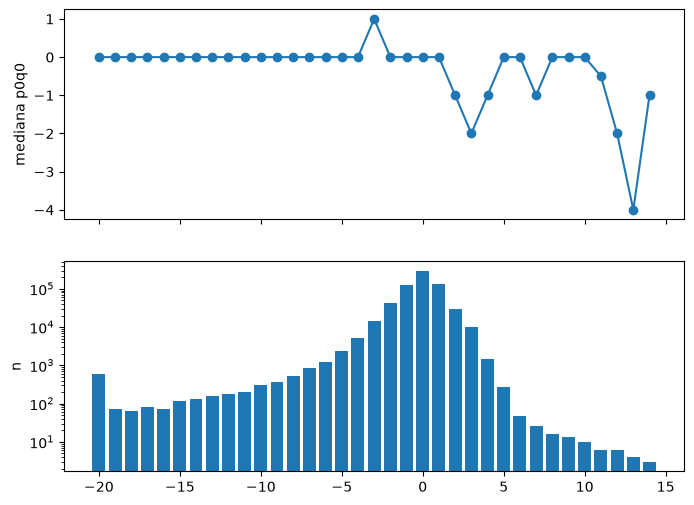

In [9]:
import matplotlib.pyplot as plt

g = df.groupby('p2q0')['p0q0'].agg(['median', 'count'])
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
ax[0].plot(g.index, g['median'], marker='o'); ax[0].set_ylabel('mediana p0q0')
ax[1].bar(g.index, g['count']); ax[1].set_yscale('log'); ax[1].set_ylabel('n')